In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install shap -q

import pandas as pd, numpy as np, json, os, xgboost as xgb
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/nba-xgboost'
DATA_DIR, MODEL_DIR, OUT_DIR = f"{BASE}/data", f"{BASE}/models", f"{BASE}/outputs"

model = xgb.XGBClassifier()
model.load_model(f"{MODEL_DIR}/xgb_model.json")
feats = json.load(open(f"{MODEL_DIR}/feature_list.json"))

train = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=['GAME_DATE'])
test = pd.read_csv(f"{DATA_DIR}/test.csv", parse_dates=['GAME_DATE'])

X_te, y_te = test[feats], test['HOME_WIN']
print(X_te.shape, "| xgboost", xgb.__version__)

Mounted at /content/drive
(2148, 19) | xgboost 3.4.1


In [2]:
p = model.predict_proba(X_te)[:, 1]
pred = (p > 0.5).astype(int)
print("Predictions made:", len(pred))

Predictions made: 2148


In [3]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, brier_score_loss, log_loss, classification_report)

train_rate = train['HOME_WIN'].mean()

metrics = {
    'test_games': int(len(test)),
    'xgb': {
        'accuracy': accuracy_score(y_te, pred),
        'precision_home': precision_score(y_te, pred, pos_label=1),
        'recall_home': recall_score(y_te, pred, pos_label=1),
        'precision_away': precision_score(y_te, pred, pos_label=0),
        'recall_away': recall_score(y_te, pred, pos_label=0),
        'macro_f1': f1_score(y_te, pred, average='macro'),
        'brier': brier_score_loss(y_te, p),
        'log_loss': log_loss(y_te, p),
    },
    'baseline': {
        'accuracy': y_te.mean(),
        'precision_home': y_te.mean(),
        'recall_home': 1.0,
        'macro_f1': (2*y_te.mean()/(1+y_te.mean()))/2,
        'brier': ((train_rate - y_te)**2).mean(),
    },
}
metrics['xgb_gain_over_baseline'] = metrics['xgb']['accuracy'] - metrics['baseline']['accuracy']

for k, v in metrics['xgb'].items():
    print(f"{k:16s} {v:.4f}")
print("Baseline accuracy:", round(metrics['baseline']['accuracy'], 4))
print("Gain over baseline:", round(metrics['xgb_gain_over_baseline'], 4))
print(classification_report(y_te, pred, target_names=['Away win', 'Home win']))

accuracy         0.6494
precision_home   0.6548
recall_home      0.7560
precision_away   0.6403
recall_away      0.5215
macro_f1         0.6383
brier            0.2173
log_loss         0.6242
Baseline accuracy: 0.5456
Gain over baseline: 0.1038
              precision    recall  f1-score   support

    Away win       0.64      0.52      0.57       976
    Home win       0.65      0.76      0.70      1172

    accuracy                           0.65      2148
   macro avg       0.65      0.64      0.64      2148
weighted avg       0.65      0.65      0.64      2148



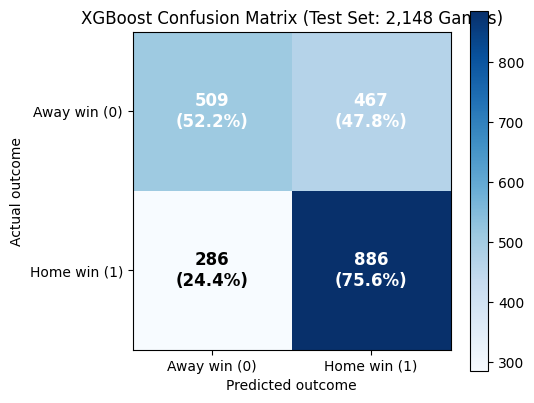

In [4]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_te, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)", ha='center', va='center',
                color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=12, fontweight='bold')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Away win (0)', 'Home win (1)'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Away win (0)', 'Home win (1)'])
ax.set_xlabel('Predicted outcome'); ax.set_ylabel('Actual outcome')
ax.set_title(f'XGBoost Confusion Matrix (Test Set: {len(test):,} Games)')
plt.colorbar(im); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=200); plt.show()

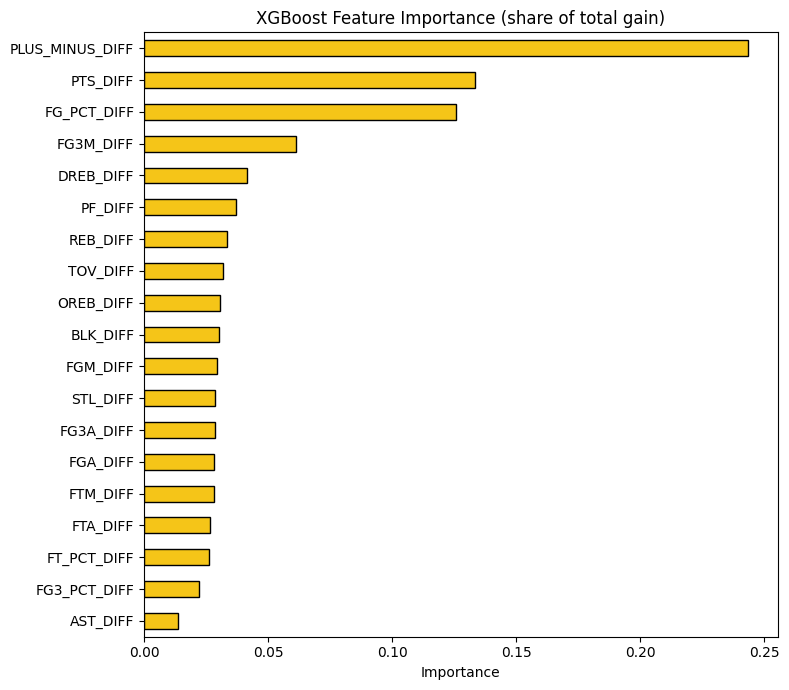

PLUS_MINUS_DIFF    0.243
PTS_DIFF           0.133
FG_PCT_DIFF        0.126
FG3M_DIFF          0.061
DREB_DIFF          0.041
dtype: float64


In [5]:
imp = pd.Series(model.get_booster().get_score(importance_type='gain'))
imp = imp.reindex(feats).fillna(0)
imp = (imp / imp.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
imp.plot(kind='barh', color='#F5C518', edgecolor='black', ax=ax)
ax.set_title('XGBoost Feature Importance (share of total gain)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/feature_importance.png", dpi=200); plt.show()
print(imp.sort_values(ascending=False).head(5).round(3))

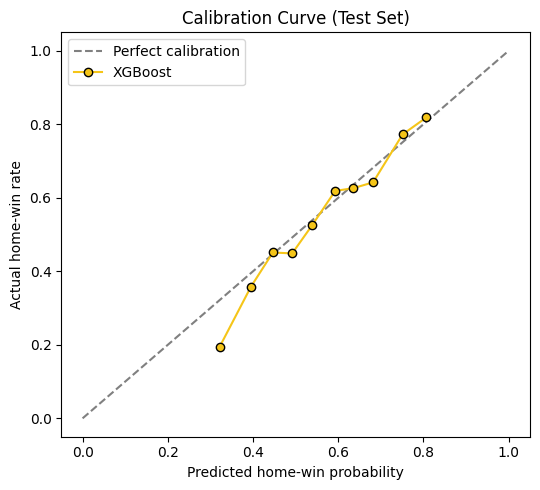

In [6]:
from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy='quantile')

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(mean_pred, frac_pos, 'o-', color='#F5C518', markeredgecolor='black', label='XGBoost')
ax.set_xlabel('Predicted home-win probability')
ax.set_ylabel('Actual home-win rate')
ax.set_title('Calibration Curve (Test Set)')
ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/calibration_curve.png", dpi=200); plt.show()

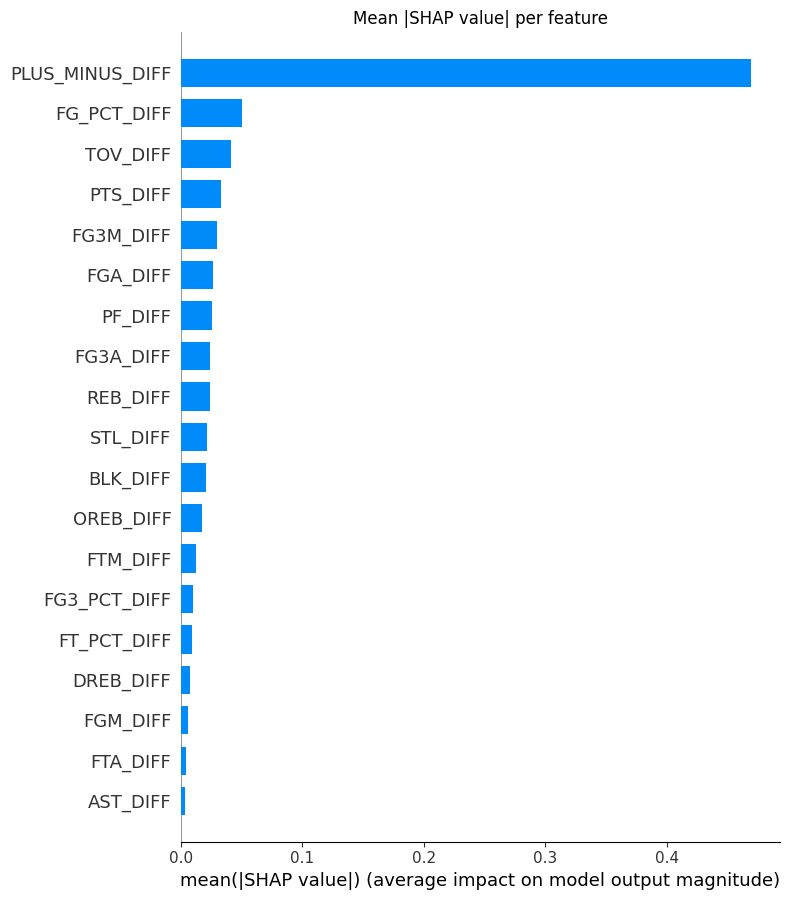

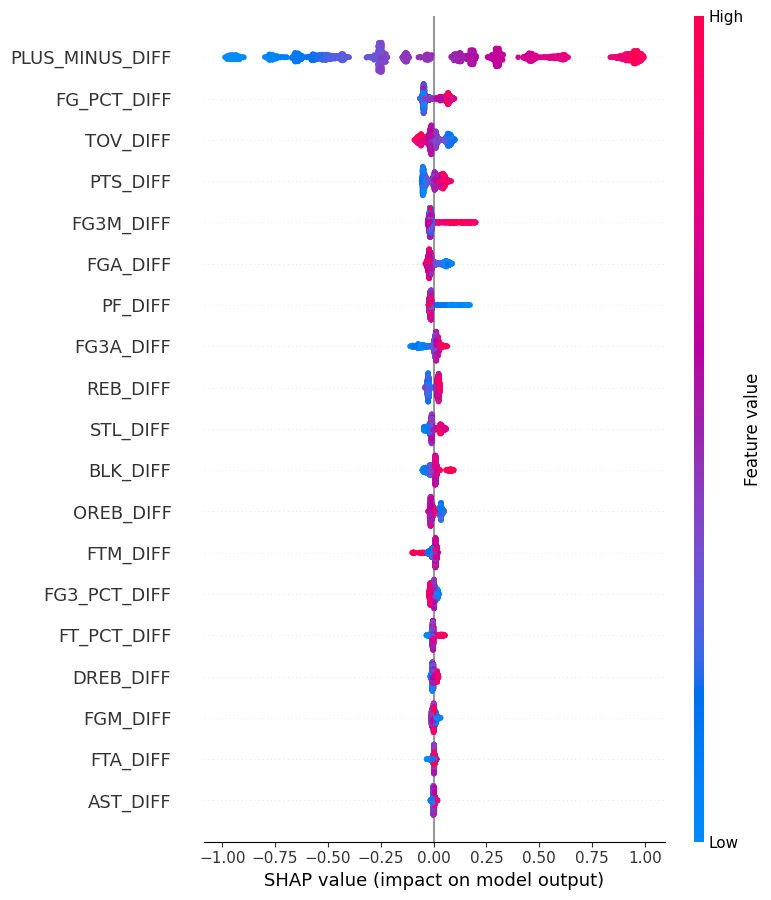

In [7]:
import shap
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_te)

plt.figure()
shap.summary_plot(sv, X_te, plot_type='bar', show=False)
plt.title('Mean |SHAP value| per feature')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/shap_importance.png", dpi=200, bbox_inches='tight'); plt.show()

plt.figure()
shap.summary_plot(sv, X_te, show=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/shap_summary.png", dpi=200, bbox_inches='tight'); plt.show()

In [8]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    return float(o) if isinstance(o, (np.floating, float)) else o

metrics['xgboost_version'] = xgb.__version__
json.dump(clean(metrics), open(f"{MODEL_DIR}/metrics.json", "w"), indent=2)

table = pd.DataFrame([
    ['Naive Baseline (always home)', metrics['baseline']['accuracy'], metrics['baseline']['precision_home'],
     metrics['baseline']['recall_home'], metrics['baseline']['macro_f1'], metrics['baseline']['brier']],
    ['XGBoost', metrics['xgb']['accuracy'], metrics['xgb']['precision_home'],
     metrics['xgb']['recall_home'], metrics['xgb']['macro_f1'], metrics['xgb']['brier']],
], columns=['Model', 'Accuracy', 'Precision (Home)', 'Recall (Home)', 'Macro F1', 'Brier'])
table.round(4).to_csv(f"{OUT_DIR}/results_table.csv", index=False)
table.round(4)

,Model,Accuracy,Precision (Home),Recall (Home),Macro F1,Brier
0,Naive Baseline (always home),0.5456,0.5456,1.000,0.3530,0.2482
1,XGBoost,0.6494,0.6548,0.756,0.6383,0.2173


In [11]:
from nba_api.stats.static import teams as nba_teams

FEATURES = [f.replace('_DIFF', '') for f in feats]
clean_df = pd.read_csv(f"{DATA_DIR}/games_clean.csv", parse_dates=['GAME_DATE'])
clean_df = clean_df.sort_values(['TEAM_ID', 'GAME_DATE', 'GAME_ID'])

last10 = clean_df.groupby('TEAM_ID').tail(10)
means = last10.groupby('TEAM_ID')[FEATURES].mean()
last_date = clean_df.groupby('TEAM_ID')['GAME_DATE'].max()
names = {t['id']: t for t in nba_teams.get_teams()}

lookup = {
    'as_of': str(clean_df['GAME_DATE'].max().date()),
    'window': 10,
    'teams': [
        {'team_id': int(tid), 'abbr': names[tid]['abbreviation'],
         'name': names[tid]['full_name'],
         'last_game': str(last_date[tid].date()),
         'stats': {f: float(means.loc[tid, f]) for f in FEATURES}}
        for tid in means.index if tid in names
    ],
}
json.dump(lookup, open(f"{MODEL_DIR}/team_stats.json", "w"), indent=2)
print(len(lookup['teams']), "teams | stats as of", lookup['as_of'])

30 teams | stats as of 2026-04-12


In [12]:
def predict_matchup(home_abbr, away_abbr):
    t = {x['abbr']: x for x in lookup['teams']}
    h, a = t[home_abbr]['stats'], t[away_abbr]['stats']
    row = pd.DataFrame([{f"{f}_DIFF": h[f] - a[f] for f in FEATURES}])[feats]
    prob = float(model.predict_proba(row)[:, 1][0])
    contrib = pd.Series(explainer.shap_values(row)[0], index=feats)
    return prob, contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)

prob, top = predict_matchup('BOS', 'LAL')
print(f"BOS (home) vs LAL: home win probability {prob:.1%}")
print(top.round(3))

prob2, _ = predict_matchup('LAL', 'BOS')
print(f"LAL (home) vs BOS: home win probability {prob2:.1%}")

BOS (home) vs LAL: home win probability 70.8%
PLUS_MINUS_DIFF    0.434
FG3M_DIFF          0.133
TOV_DIFF           0.073
FG3A_DIFF          0.051
PTS_DIFF           0.030
dtype: float32
LAL (home) vs BOS: home win probability 47.0%
